# **CA3** - Classification of Wine

# **Group 6** - Narges Zareigolbaghi & Kachina Aschenberg Øwre 

**Use machine learning to develop a system/classifier capable of distinguishing between high-quality and low-quality wines based on measurable characteristics.**

*Your task is to create a classifier that uses the available wine characteristics to sort the wines into the correct categories.*

*The dataset contains several physicochemical properties of wine that can be used to predict its quality. These properties describe characteristics such as acidity, sugar content, density, sulphates, alcohol level, and other chemical measurements.*

*The success of your classification system depends on your ability to explore the data, identify useful patterns, and train a model that can accurately distinguish between good and bad wines.*

Sample: one row, one wine

Feature: Attribute, variable, column (pH, alcohol)

Target: quality (0=bad, 1=good)

Feature matrix: X, all columns together (835 rows x 11 columns)

Target vector: y, the target column (835 values of 0 or 1)

### Imports

In [ ]:
import numpy as np                 # numbers and arrays
import pandas as pd                # tables (DataFrames)
import matplotlib.pyplot as plt    # basic plotting
import seaborn as sns              # nicer statistical plots on top of matplotlib
import sklearn as skl              # machine learning library

from sklearn.model_selection import train_test_split # splits data into training and test sets
from sklearn.preprocessing import StandardScaler # rescales features to have mean 0 and variance 1
from sklearn.linear_model import Perceptron, LogisticRegression # linear classifiers, baseline for comparison and neural networks
from sklearn.svm import SVC     # support vector machine, a more powerful linear classifier
from sklearn.tree import DecisionTreeClassifier # decision tree, a non-linear classifier
from sklearn.ensemble import RandomForestClassifier     # random forest, a more powerful non-linear classifier
from sklearn.neighbors import KNeighborsClassifier  # k-nearest neighbors, a non-linear classifier

### Reading data

In [15]:
train = pd.read_csv("train.csv")                 # 11 features + quality + Id
test = pd.read_csv("test.csv")                   # 11 features + Id, no quality
sample = pd.read_csv("sample_submission.csv")    # the format Kaggle expects
print("train:", train.shape, " test:", test.shape, " sample:", sample.shape)

# The feature columns: everything except the target and the row label
features = [col for col in train.columns if col not in ("quality", "Id")] 
print(len(features), "features:", features)

train: (835, 13)  test: (209, 12)  sample: (209, 2)
11 features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


### Data exploration and visualisation

In [ ]:
train.info()                       # column types and non-null counts
train.describe().T                 # .T turns the table: one row per feature
print(train["quality"].value_counts()) # count of each quality value
print("Missing values:", train.isnull().sum().sum()) # total number of missing values in the training set
print("Duplicate rows (ignoring Id):", train.duplicated(subset=features + ["quality"]).sum()) # count of duplicate rows in the training set, ignoring the Id column

<class 'pandas.DataFrame'>
RangeIndex: 835 entries, 0 to 834
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         835 non-null    float64
 1   volatile acidity      835 non-null    float64
 2   citric acid           835 non-null    float64
 3   residual sugar        835 non-null    float64
 4   chlorides             835 non-null    float64
 5   free sulfur dioxide   835 non-null    float64
 6   total sulfur dioxide  835 non-null    float64
 7   density               835 non-null    float64
 8   pH                    835 non-null    float64
 9   sulphates             835 non-null    float64
 10  alcohol               835 non-null    float64
 11  quality               835 non-null    int64  
 12  Id                    835 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 84.9 KB
quality
1    418
0    417
Name: count, dtype: int64
Missing values: 0
Duplicate rows (ign

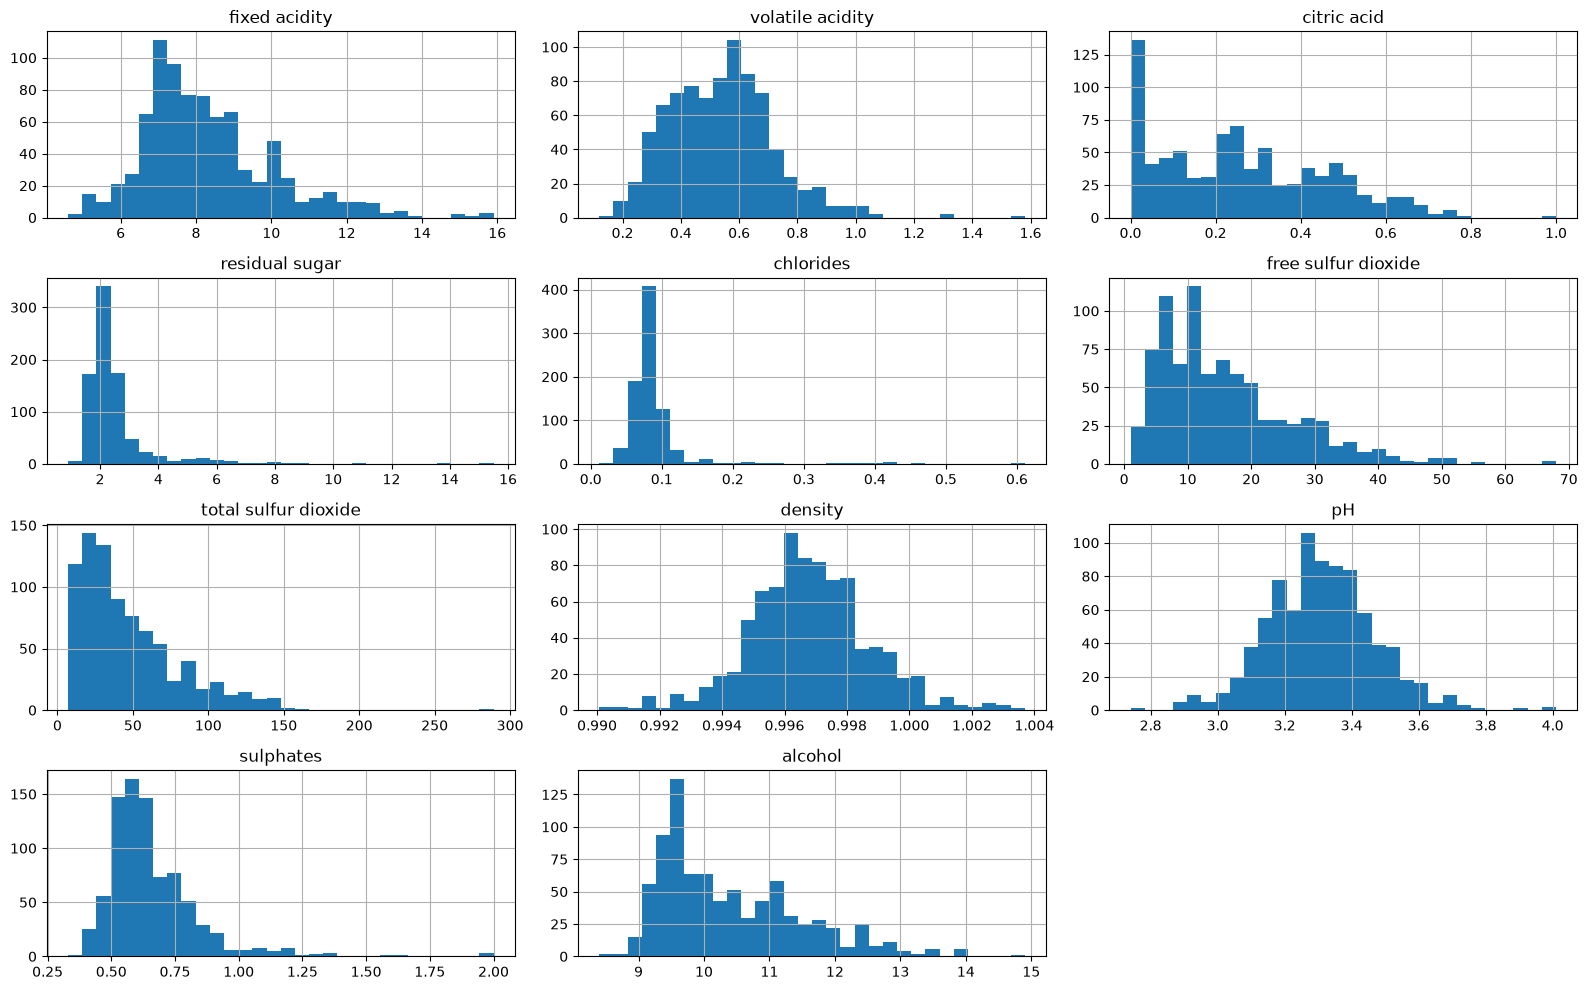

In [17]:
train[features].hist(figsize=(16, 10), bins=30)
plt.tight_layout()
plt.show()

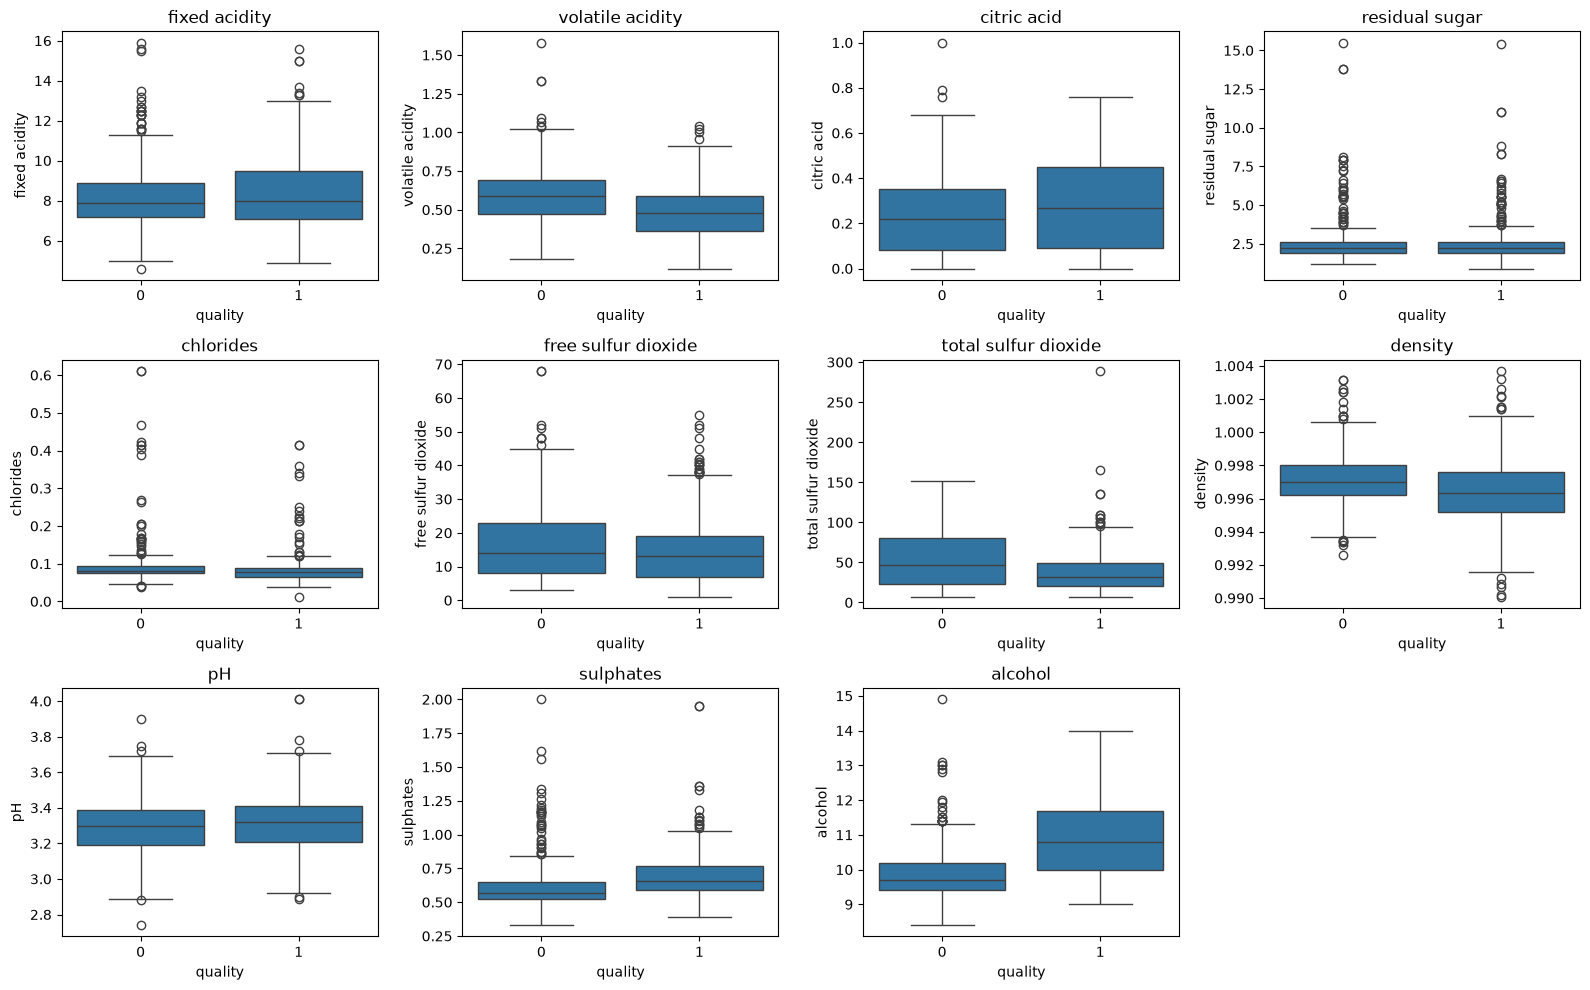

In [18]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))     # 3 x 4 grid: 12 panels for 11 features
for ax, col in zip(axes.flatten(), features):          # one panel per feature
    sns.boxplot(data=train, x="quality", y=col, ax=ax)
    ax.set_title(col)
axes.flatten()[-1].set_visible(False)                  # hide the empty 12th panel
plt.tight_layout()
plt.show()

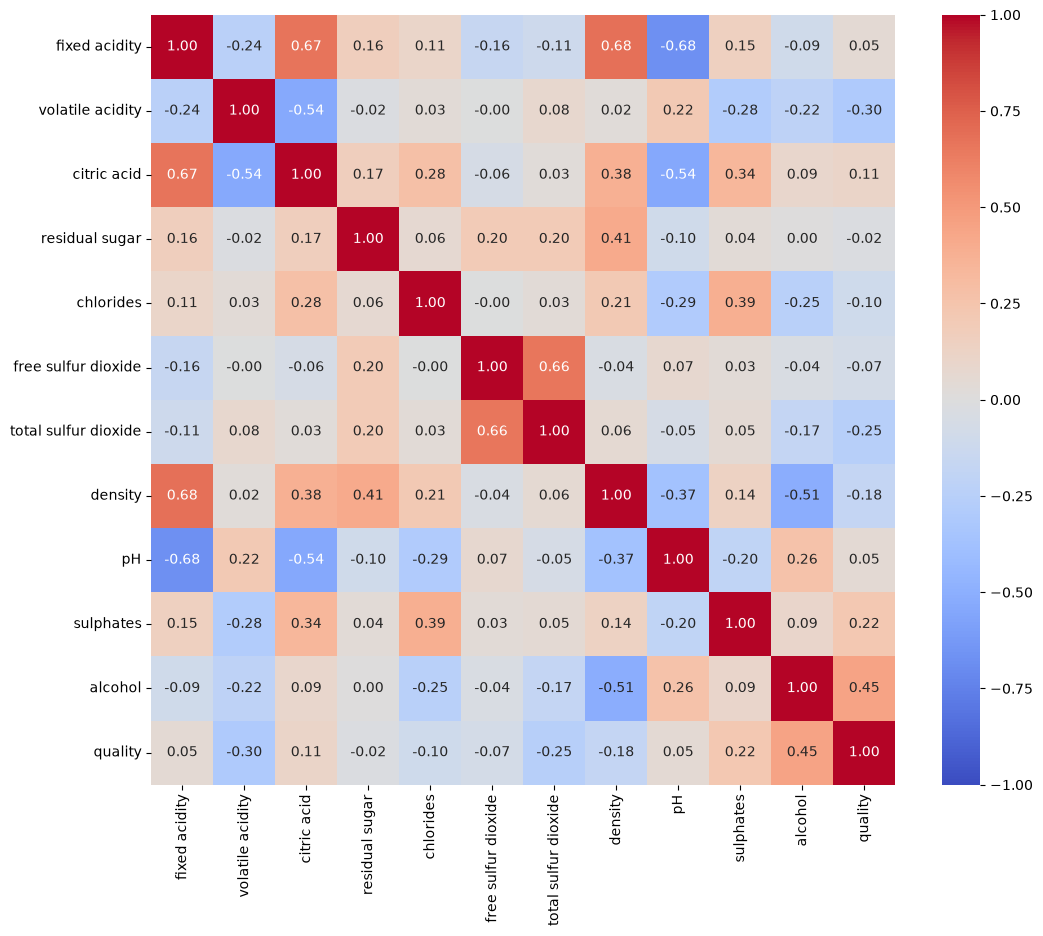

volatile acidity       -0.302238
total sulfur dioxide   -0.250267
density                -0.179263
chlorides              -0.103287
free sulfur dioxide    -0.074444
residual sugar         -0.020452
pH                      0.049578
fixed acidity           0.051339
citric acid             0.111017
sulphates               0.219372
alcohol                 0.451935
Name: quality, dtype: float64


In [10]:
corr = train[features + ["quality"]].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

print(corr["quality"].drop("quality").sort_values())   # correlation of each feature with quality

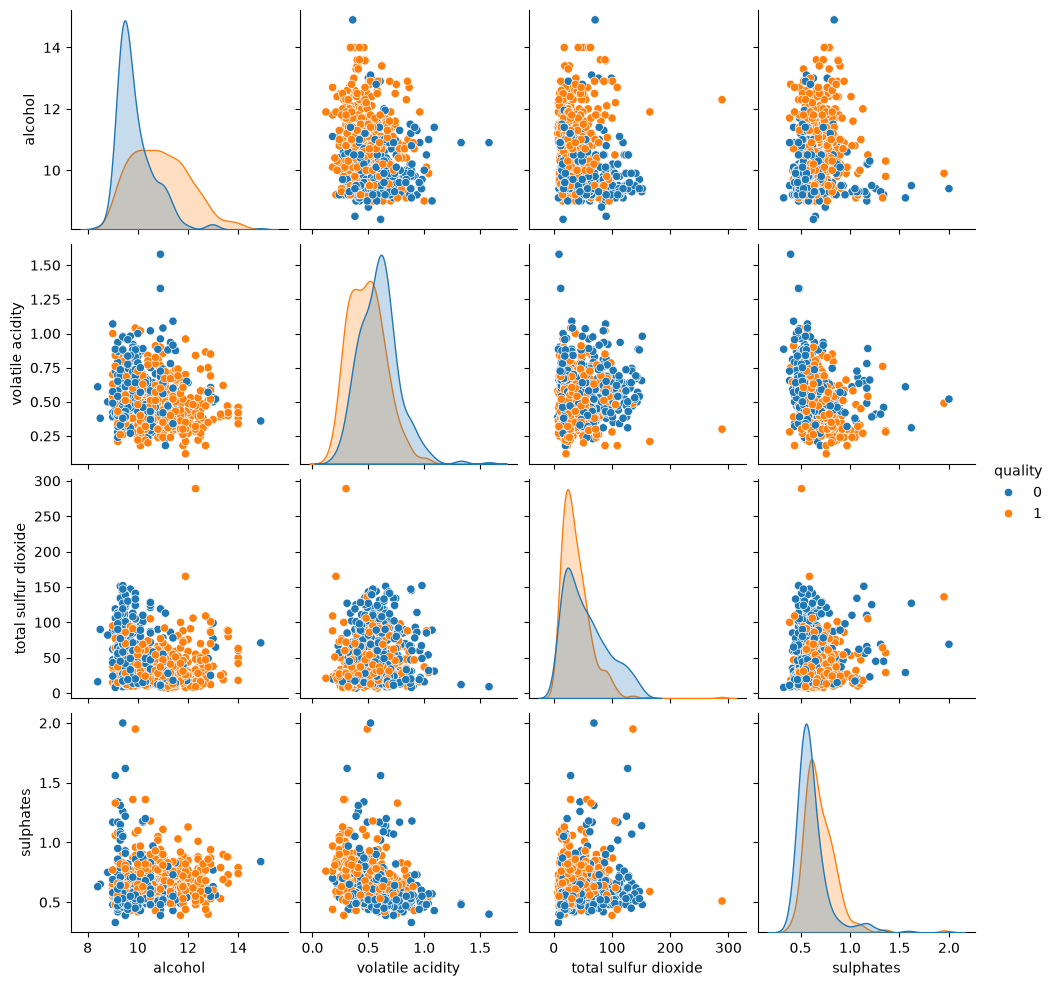

In [11]:
top = corr["quality"].drop("quality").abs().sort_values(ascending=False).index[:4].tolist()
sns.pairplot(train, vars=top, hue="quality")
plt.show()

### Data cleaning

In [19]:
data = train.drop(columns=["Id"])

# Same features but a different label? Those rows contradict each other.
dup_mask = data.duplicated(subset=features, keep=False)
conflicts = data[dup_mask].groupby(features)["quality"].nunique()
print("Duplicate groups with conflicting labels:", (conflicts > 1).sum())

# Keep the first copy of every exact duplicate
data = data.drop_duplicates()
print("Rows after removing exact duplicates:", len(data))

Duplicate groups with conflicting labels: 0
Rows after removing exact duplicates: 760


In [20]:
print("Negative values:", (data[features] < 0).sum().sum())
print("pH outside 2.5 to 4.5:", ((data["pH"] < 2.5) | (data["pH"] > 4.5)).sum())
print("Alcohol outside 5 to 16 %:", ((data["alcohol"] < 5) | (data["alcohol"] > 16)).sum())

Negative values: 0
pH outside 2.5 to 4.5: 0
Alcohol outside 5 to 16 %: 0


In [21]:
z = (data[features] - data[features].mean()) / data[features].std()
print((z.abs() > 3).sum())                         # outliers per feature
outlier_rows = (z.abs() > 3).any(axis=1)           # True if ANY feature has |z| > 3
print("Rows with |z| > 3 in any feature:", outlier_rows.sum())

fixed acidity            7
volatile acidity         3
citric acid              1
residual sugar          15
chlorides               16
free sulfur dioxide      9
total sulfur dioxide     4
density                 10
pH                       4
sulphates               12
alcohol                  6
dtype: int64
Rows with |z| > 3 in any feature: 68


### Data preprocessing and visualisation

In [22]:
X = data[features].to_numpy()        # one row per wine, one column per feature
y = data["quality"].to_numpy()

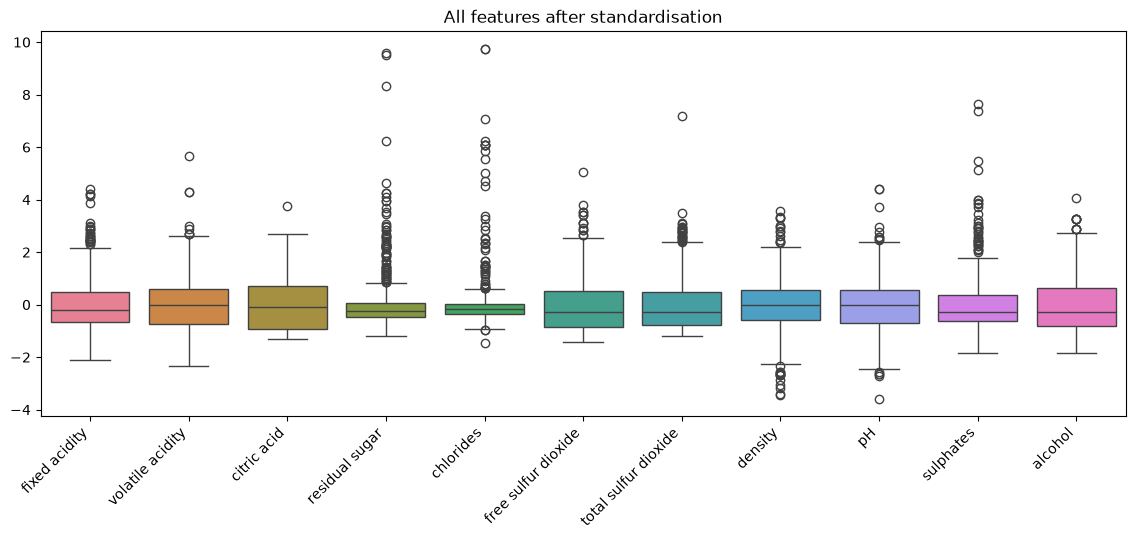

In [23]:
scaled = pd.DataFrame(StandardScaler().fit_transform(X), columns=features)
plt.figure(figsize=(14, 5))
sns.boxplot(data=scaled)
plt.xticks(rotation=45, ha="right")
plt.title("All features after standardisation")
plt.show()

In [25]:
def evaluate(make_model, X, y, n_splits=50, scale=True, drop_outliers=False):
    """Mean training accuracy, mean validation accuracy and the validation
    standard deviation over n_splits random training/validation splits."""
    train_scores, val_scores = [], []
    for rs in range(n_splits):
        # 1. A new random split, the same one for every model (random_state = rs)
        X_tr, X_va, y_tr, y_va = train_test_split(
            X, y, test_size=0.3, random_state=rs, stratify=y)

        # 2. Optional: remove outliers from the TRAINING part only
        if drop_outliers:
            z_tr = (X_tr - X_tr.mean(axis=0)) / X_tr.std(axis=0)
            keep = (np.abs(z_tr) < 3).all(axis=1)
            X_tr, y_tr = X_tr[keep], y_tr[keep]

        # 3. Scale with a scaler fitted on the training part only
        if scale:
            sc = StandardScaler()
            X_tr = sc.fit_transform(X_tr)
            X_va = sc.transform(X_va)

        # 4. A fresh model, trained and scored
        model = make_model()
        model.fit(X_tr, y_tr)
        train_scores.append(model.score(X_tr, y_tr))
        val_scores.append(model.score(X_va, y_va))

    return np.mean(train_scores), np.mean(val_scores), np.std(val_scores)

tr, va, sd = evaluate(lambda: LogisticRegression(max_iter=1000), X, y)
print(f"train {tr:.3f}, validation {va:.3f} ± {sd:.3f}")

train 0.750, validation 0.743 ± 0.028


### Modelling

In [ ]:
# y_pred_kaggle = model.predict(X_test_scaled)                   # 0/1 for each row of test.csv, same order
# submission = pd.DataFrame(y_pred_kaggle, columns=["quality"])  # one column; rows numbered 0..208 automatically
# submission.index.name = "ID"                                   # the row numbers become the "ID" column
# submission.to_csv("submission.csv")                            # writes the header ID,quality plus one row per wine

In [ ]:

# Results are stored in a list of dictionaries, where each dictionary contains the model name, settings, training accuracy, validation accuracy, and standard deviation of the validation accuracy. This allows for easy comparison of different models and their hyperparameter settings.
results = []     # one dictionary per classifier and setting
for eta in [0.0001, 0.001, 0.01, 0.1, 1.0]:
    tr, va, sd = evaluate(lambda: Perceptron(eta0=eta, max_iter=100, random_state=1), X, y)
    results.append({"model": "Perceptron", "settings": f"eta0={eta}",
                    "train": tr, "val": va, "std": sd})

In [29]:
# Results are stored in a list of dictionaries, where each dictionary contains the model name, settings, training accuracy, validation accuracy, and standard deviation of the validation accuracy. This allows for easy comparison of different models and their hyperparameter settings.
results = []     # one dictionary per classifier and setting
for c in [0.001, 0.01, 0.1, 1, 10, 100, 1000]:
    tr, va, sd = evaluate(lambda: LogisticRegression(C=c, max_iter=1000), X, y)
    results.append({"model": "Logistic regression", "settings": f"C={c}",
                    "train": tr, "val": va, "std": sd})

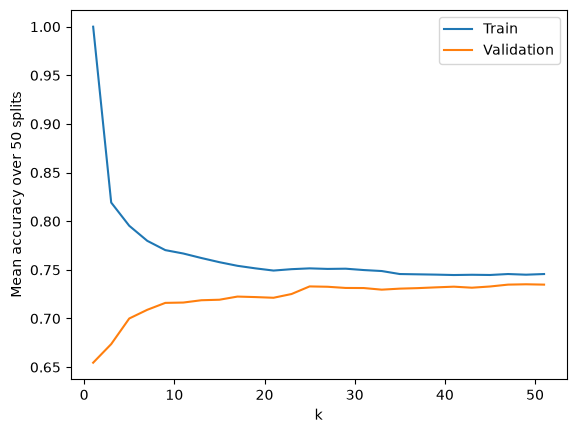

In [31]:
#
results = []     # one dictionary per classifier and setting
for k in range(1, 52, 2):          # odd k from 1 to 51
    for p in [1, 2]:               # 1 = Manhattan, 2 = Euclidean
        tr, va, sd = evaluate(lambda: KNeighborsClassifier(n_neighbors=k, p=p), X, y)
        results.append({"model": "KNN", "settings": f"k={k}, p={p}", "k": k, "p": p,
                        "train": tr, "val": va, "std": sd})

# Training vs validation accuracy as k grows (Euclidean distance)
res = pd.DataFrame(results)
knn_p2 = res[(res["model"] == "KNN") & (res["p"] == 2)]
plt.plot(knn_p2["k"], knn_p2["train"], label="Train")
plt.plot(knn_p2["k"], knn_p2["val"], label="Validation")
plt.xlabel("k")
plt.ylabel("Mean accuracy over 50 splits")
plt.legend()
plt.show()

### Final evaluation

### Kaggle submission